# Experiment summary: choosing the Best model

This notebook compares the three Runs (one per candidate), shows their TensorBoard curves (Optional 2), picks the **Best model** and holds the write-up (TODO 2).
Run it after all three `1_train_model_<candidate>.ipynb` notebooks have finished. Each of them writes `results/<candidate>.json`.

| Candidate | Pretrained model | Notebook |
|---|---|---|
| `efficientdet_d1` | EfficientDet D1 640x640 (baseline) | [1_train_model_efficientdet_d1.ipynb](1_train_model_efficientdet_d1.ipynb) |
| `ssd_mobilenet_v2_fpnlite_640` | SSD MobileNet V2 FPNLite 640x640 | [1_train_model_ssd_mobilenet_v2_fpnlite_640.ipynb](1_train_model_ssd_mobilenet_v2_fpnlite_640.ipynb) |
| `ssd_resnet50_v1_fpn_640` | SSD ResNet50 V1 FPN 640x640 (RetinaNet50) | [1_train_model_ssd_resnet50_v1_fpn_640.ipynb](1_train_model_ssd_resnet50_v1_fpn_640.ipynb) |

**Shared recipe (identical for every Run):** 2,000 steps at batch 8, momentum 0.9, cosine decay from a base learning rate of 0.02 with 200 warm-up steps from 0.002, fp32,
random horizontal flip + random scale/crop/pad to 640, fine-tuned from COCO detection checkpoints, `num_classes: 4` (label map ids 1, 2, 4).
Only the architecture changes between Runs. See `docs/adr/0001` and `docs/adr/0002` for why.

In [1]:
%pip install -q tensorboard pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import pandas as pd

import tb_helpers as tb

# On-demand price of ml.g5.xlarge training in us-east-1 when this was written; check the AWS pricing page.
G5_XLARGE_TRAINING_USD_PER_HOUR = 1.408

registry = json.loads(Path("candidates.json").read_text())["candidates"]
runs = {}
for entry in registry:
    path = Path("results") / f"{entry['key']}.json"
    if path.is_file():
        runs[entry["key"]] = json.loads(path.read_text())
    else:
        print(f"Missing {path}: run 1_train_model_{entry['key']}.ipynb first")
print("Runs found:", list(runs))

Runs found: ['efficientdet_d1', 'ssd_mobilenet_v2_fpnlite_640', 'ssd_resnet50_v1_fpn_640']


In [3]:
# Download each Run's TensorBoard events from S3 and load them as tidy frames.
s3 = boto3.client("s3")
scalars = {}
for key, run in runs.items():
    bucket, _, prefix = run["tensorboard_s3_prefix"].removeprefix("s3://").partition("/")
    dirs = tb.download_event_files(s3, bucket, prefix, Path("/tmp/tb") / key)
    scalars[key] = {split: tb.load_scalars(d) for split, d in dirs.items()}
    print(key, {split: len(df) for split, df in scalars[key].items()})

efficientdet_d1 {'eval': 16, 'train': 120}


ssd_mobilenet_v2_fpnlite_640 {'eval': 16, 'train': 120}


ssd_resnet50_v1_fpn_640 {'eval': 16, 'train': 120}


## Comparison table

mAP is COCO mAP@[.5:.95] on the validation split. The training loss is the mean over the last 10% of steps, and the validation loss comes from the single evaluation of the final checkpoint.

In [4]:
empty = pd.DataFrame(columns=["step", "tag", "value"])
summaries = {
    key: tb.summarize_run(s.get("train", empty), s.get("eval", empty)) for key, s in scalars.items()
}
table = pd.DataFrame(summaries).T
table["train minutes"] = [runs[k]["training_seconds"] / 60 for k in table.index]
table["approx cost USD"] = [runs[k]["billable_seconds"] / 3600 * G5_XLARGE_TRAINING_USD_PER_HOUR for k in table.index]
table = table.sort_values("mAP", ascending=False)

columns = ["mAP", "mAP@0.5", "mAP small", "mAP medium", "mAP large", "AR@100",
           "train Loss/total_loss", "val Loss/total_loss",
           "train Loss/classification_loss", "val Loss/classification_loss",
           "train Loss/localization_loss", "val Loss/localization_loss",
           "train minutes", "approx cost USD"]
table[columns].style.format("{:.3f}", na_rep="n/a")

,mAP,mAP@0.5,mAP small,mAP medium,mAP large,AR@100,train Loss/total_loss,val Loss/total_loss,train Loss/classification_loss,val Loss/classification_loss,train Loss/localization_loss,val Loss/localization_loss,train minutes,approx cost USD
ssd_resnet50_v1_fpn_640,0.094,0.189,0.043,0.317,0.480,0.135,0.626,0.821,0.166,0.221,0.206,0.346,18.650,0.438
ssd_mobilenet_v2_fpnlite_640,0.085,0.177,0.035,0.299,0.608,0.129,0.670,0.801,0.220,0.263,0.299,0.387,12.550,0.295
efficientdet_d1,0.081,0.184,0.033,0.300,0.420,0.122,0.255,0.309,0.213,0.262,0.012,0.017,31.933,0.749


In [5]:
best_key = tb.pick_best(summaries)
best = {"candidate": best_key, "model_artifact": runs[best_key]["model_artifact"], "mAP": summaries[best_key]["mAP"]}
Path("results").mkdir(exist_ok=True)
Path("results/best_model.json").write_text(json.dumps(best, indent=2) + "\n")
table[columns].to_csv("results/summary.csv")
print(json.dumps(best, indent=2))

{
  "candidate": "ssd_resnet50_v1_fpn_640",
  "model_artifact": "s3://sagemaker-us-east-1-403723872191/tf2-od-ssd-resnet50-v1-fpn-640/tf2-od-ssd-resnet50-v1-fpn-640-2026-11-05-16-59-55-464/output/model.tar.gz",
  "mAP": 0.09432751685380936
}


## TensorBoard graphs (Optional 2)

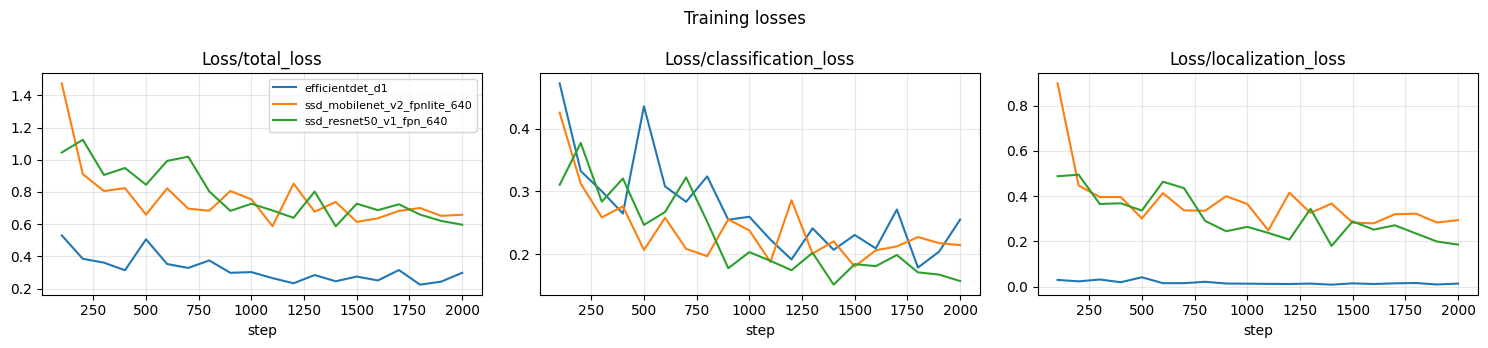

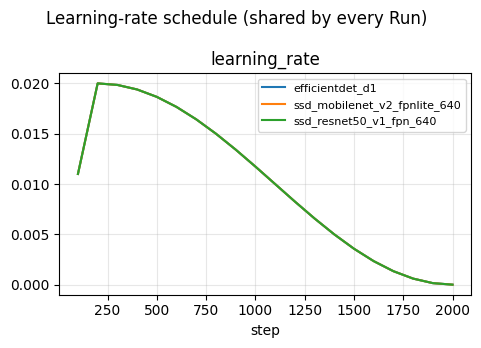

In [6]:
def plot_train_curves(tags, title):
    fig, axes = plt.subplots(1, len(tags), figsize=(5 * len(tags), 3.5), squeeze=False)
    for ax, tag in zip(axes[0], tags):
        for key, s in scalars.items():
            df = s.get("train", empty)
            df = df[df["tag"] == tag]
            ax.plot(df["step"], df["value"], label=key)
        ax.set_title(tag)
        ax.set_xlabel("step")
        ax.grid(alpha=0.3)
    axes[0][0].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    return fig

plot_train_curves(["Loss/total_loss", "Loss/classification_loss", "Loss/localization_loss"], "Training losses")
plot_train_curves(["learning_rate"], "Learning-rate schedule (shared by every Run)");

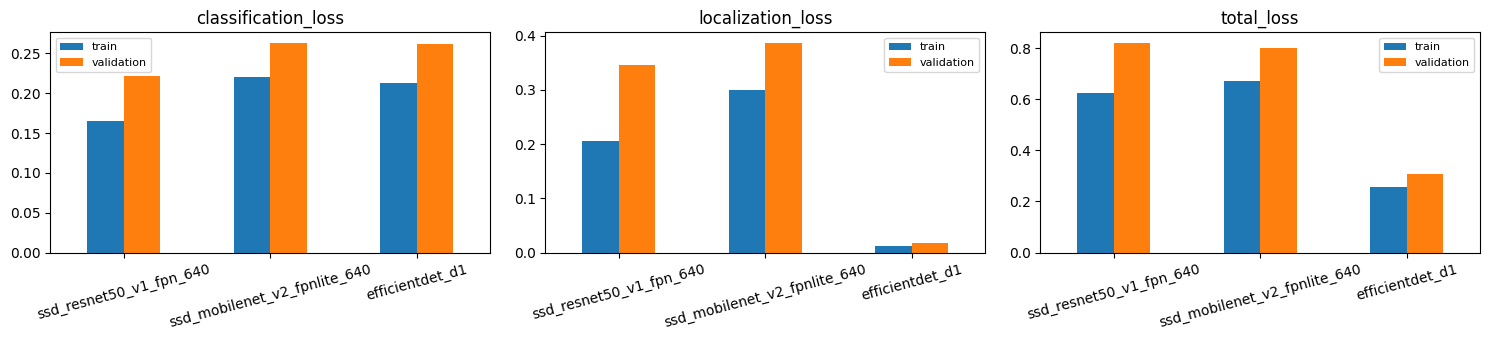

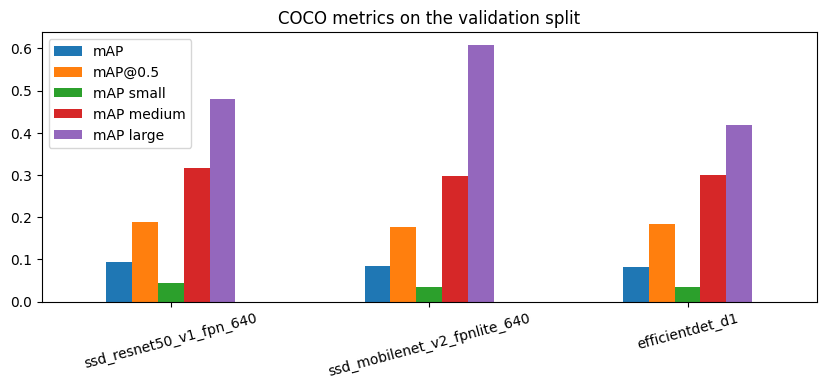

In [7]:
# Training vs validation loss at the end of each Run
loss_parts = ["classification_loss", "localization_loss", "total_loss"]
fig, axes = plt.subplots(1, len(loss_parts), figsize=(15, 3.5))
for ax, part in zip(axes, loss_parts):
    table[[f"train Loss/{part}", f"val Loss/{part}"]].plot.bar(ax=ax, rot=15)
    ax.set_title(part)
    ax.legend(["train", "validation"], fontsize=8)
fig.tight_layout()

ax = table[["mAP", "mAP@0.5", "mAP small", "mAP medium", "mAP large"]].plot.bar(figsize=(10, 3.5), rot=15)
ax.set_title("COCO metrics on the validation split");

## Write-up (TODO 2)

### Experiments

We fine-tuned three COCO-pretrained detectors from the TF2 Model Zoo with **one shared training recipe**, so the architecture is the only thing that changes between Runs:
EfficientDet D1 (the project's default, used as the baseline), SSD MobileNet V2 FPNLite 640 and SSD ResNet50 V1 FPN 640 (RetinaNet50).
Every Run used 2,000 steps at batch 8, momentum 0.9, cosine decay from a base learning rate of 0.02 after 200 warm-up steps, horizontal flip plus random scale/crop/pad augmentation, on one `ml.g5.xlarge`.

Two problems in the starter configuration were fixed for every Run before training:

1. **Cyclists could not be learned.** The label map uses ids 1, 2 and **4**, but the config declared `num_classes: 3`. The OD API one-hot encodes class ids with depth `num_classes`, so cyclist boxes would have been treated as background. We set `num_classes: 4` and left id 3 unused (`docs/adr/0001`).
2. **The learning rate never left warm-up.** The EfficientDet recipe (2,500 warm-up steps, 300k cosine steps, base 0.08 for batch 128 on TPU) was being used for a 2,000-step job at batch 8. We sized the schedule to the real job (`docs/adr/0002`).

### Results (validation split, COCO metrics)

| Model | mAP @[.5:.95] | mAP@0.5 | mAP small | mAP medium | mAP large | AR@100 | train total loss | val total loss | training time |
|---|---|---|---|---|---|---|---|---|---|
| **SSD ResNet50 V1 FPN 640** | **0.094** | **0.189** | **0.043** | **0.317** | 0.480 | **0.135** | 0.626 | 0.821 | 18.6 min |
| SSD MobileNet V2 FPNLite 640 | 0.085 | 0.177 | 0.035 | 0.299 | **0.608** | 0.129 | 0.670 | 0.801 | 12.6 min |
| EfficientDet D1 (baseline) | 0.081 | 0.184 | 0.034 | 0.300 | 0.420 | 0.122 | 0.255 | 0.309 | 31.9 min |

**Best model: SSD ResNet50 V1 FPN 640 (RetinaNet50).** It has the highest mAP. It also wins the tie-break we fixed in advance: when two Runs are within 0.01 mAP (ResNet50 leads MobileNet by 0.009), the better **small-object** mAP decides, because most pedestrians and cyclists are small. ResNet50 has 0.043 against 0.035.
It is the one deployed in `2_deploy_model.ipynb`. MobileNet would be the pick if inference latency mattered more than accuracy: it trains in two thirds of the time and is far better on large objects.

### How does the validation loss compare to the training loss?

For every model the **validation loss is higher than the training loss**: by 31% for ResNet50 (0.82 vs 0.63), 20% for MobileNet (0.80 vs 0.67) and 21% for EfficientDet (0.31 vs 0.26).
The gap comes mostly from **localization** (ResNet50: 0.35 vs 0.21; MobileNet: 0.39 vs 0.30). Classification loss rises less (ResNet50: 0.22 vs 0.17).
Absolute losses are **not comparable across architectures**. EfficientDet's box coder uses scale factors of 1 while the two SSDs use 10/10/5/5, so its localization loss is roughly an order of magnitude smaller by construction. Only the train/validation gap within a model is meaningful, and mAP is the cross-model comparison.

### Did you expect such behavior from the losses / metrics?

Yes.
* **A train/validation gap was expected.** The validation drives are different scenes, in different light, from the training drives. The gap is moderate rather than large, which fits a model that is still **under-trained**: 2,000 steps at batch 8 is about 16k images, and the best model's training loss is still falling over the last 500 steps (0.73 to 0.60). The other two are noisy and flatten only because the cosine schedule takes the learning rate to zero. Augmentation runs only during training, which pushes training loss up and narrows the gap, so the real generalization gap is somewhat larger than the numbers suggest.
* **Low absolute mAP (0.08 to 0.09) was expected** for so short a schedule. The pattern across object sizes is the telling part: all three models reach 0.42 to 0.61 mAP on large objects but only 0.03 to 0.04 on small ones. Distant pedestrians and cyclists are a few pixels high in a 640×640 image, which is the hardest case for these one-stage detectors.
* **The ranking was expected**: the strongest backbone (ResNet50 FPN) leads on mAP and on small objects. EfficientDet D1 needed the most time per step (0.70 s against 0.39 s for ResNet50 and 0.22 s for MobileNet) without an accuracy advantage at this training length; its compound scaling usually pays off only with much longer schedules.
* **Cyclists are the weakest class.** They are rare in the training data. On the 100 test frames, at the video's 0.3 display threshold, the deployed model makes 969 vehicle boxes (best score 0.98, every frame), 1,205 pedestrian boxes (best 0.72, 93 frames) and only **3 cyclist boxes in 2 frames, with a best score of 0.37**. At the starter's 0.6 threshold no cyclist was shown at all, which is why the deploy notebook uses 0.3. The person walking a bicycle beside the bus lane in the first frames is boxed as a *pedestrian*, which is arguably right while they walk it. The lower threshold has a cost: it also draws overlapping, low-confidence duplicate boxes, mostly on parked vehicles.

### What can you do to further improve the performance of the tested models?

1. **Train longer.** ResNet50's loss is still falling at step 2,000, and none of the models has converged. 10k to 25k steps, with the same schedule rule (warm-up at 10%, cosine to the last step), is the cheapest, largest gain.
2. **Address class imbalance for cyclists.** Oversample frames that contain cyclists, or tune the focal loss's alpha and gamma. Per-class AP (`include_metrics_per_category`) would track the effect.
3. **Target small objects.** Use a higher input resolution (for example 1024), denser or smaller anchors, or a two-stage detector (Faster R-CNN), which handles small, distant pedestrians and cyclists better.
4. **Add lighting augmentation** (`random_adjust_brightness`, `random_adjust_contrast`, `random_adjust_saturation`) for the night and low-light scenes, and `random_crop_image` for scale variety.
5. **Pick the best checkpoint, not the last one.** Run continuous evaluation during training and keep the checkpoint with the best validation mAP. Also tune the inference score threshold **per class**: 0.3 suits cyclists in this under-trained model, but vehicles would look cleaner at 0.5 or higher.